# PRCP-1020: House Price Prediction

## Problem Statement

The objective of this project is to analyze the housing dataset and develop a machine learning model to accurately predict the selling price of houses based on various property features. The project also aims to understand how different house characteristics influence the selling price and provide useful recommendations for potential home buyers.

---

# Project Tasks

### Task 1: Data Analysis
Prepare a complete data analysis report on the given dataset by performing data understanding, exploratory data analysis, data preprocessing, and feature analysis.

### Task 2(a): House Price Prediction
Create a robust machine learning regression model to accurately predict the selling price of houses based on various housing features.

### Task 2(b): Feature Relationship Analysis
Determine the relationship between different house features and how they influence the selling price of houses.

### Task 3: Customer Recommendations
Provide recommendations for customers to purchase houses based on area, price, and other important property features identified during the analysis.

---

## Project Workflow

1. Import Required Libraries
2. Load the Dataset
3. Data Understanding
4. Exploratory Data Analysis (EDA)
5. Data Preprocessing
6. Feature Engineering
7. Train-Test Split
8. Model Building
9. Model Evaluation
10. Feature Importance
11. Model Comparison Report
12. Customer Recommendations
13. Report on Challenges Faced
14. Final Conclusion

# Import Required Libraries

In [3]:
# Data Manipulation
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning
from sklearn.model_selection import train_test_split

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

# Model Evaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Ignore Warnings
import warnings
warnings.filterwarnings("ignore")

## Observation

All the required Python libraries were successfully imported. These libraries will be used for data manipulation, visualization, preprocessing, regression model development, and performance evaluation throughout the project.

# Load the Dataset

In [4]:
df = pd.read_csv("data.csv")

df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## Observation

The dataset was successfully loaded into a Pandas DataFrame. The initial preview confirms that the dataset contains various numerical and categorical features describing residential properties, along with the target variable `SalePrice`, which will be used for house price prediction.

# Data Understanding

In [6]:
df.shape

(1460, 81)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [8]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [9]:
df.isnull().sum().sort_values(ascending=False)

PoolQC         1453
MiscFeature    1406
Alley          1369
Fence          1179
MasVnrType      872
               ... 
ExterQual         0
Exterior2nd       0
Exterior1st       0
RoofMatl          0
SalePrice         0
Length: 81, dtype: int64

In [10]:
df.duplicated().sum()

np.int64(0)

In [11]:
df.dtypes.value_counts()

object     43
int64      35
float64     3
Name: count, dtype: int64

## Observation

The dataset contains **1,460 house records** and **81 columns**, comprising both numerical and categorical features. The dataset includes **35 integer columns, 3 floating-point columns, and 43 categorical columns**, providing detailed information about property characteristics. No duplicate records were found. However, some features contain missing values, which will be addressed during the data preprocessing stage before model development.

# Exploratory Data Analysis (EDA)

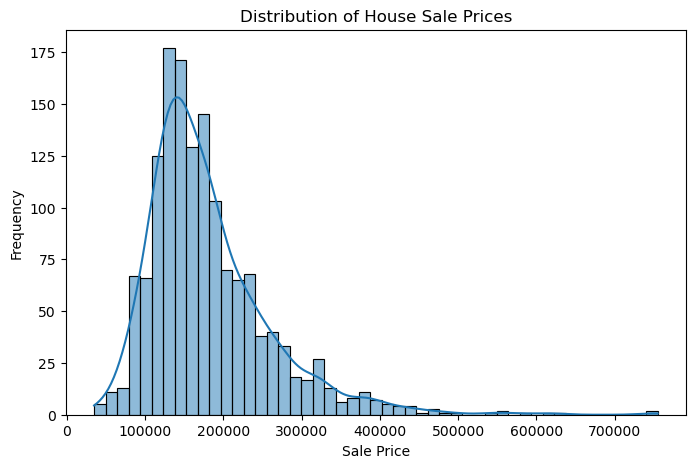

In [12]:
plt.figure(figsize=(8,5))

sns.histplot(df["SalePrice"], kde=True)

plt.title("Distribution of House Sale Prices")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")

plt.show()

## Observation

The distribution of `SalePrice` shows that most houses are concentrated within a moderate price range, while a smaller number of houses have significantly higher selling prices. This indicates that the target variable is positively skewed, with a few high-priced properties acting as potential outliers. Understanding this distribution is important for selecting appropriate regression models and evaluating prediction performance.

## Correlation Analysis

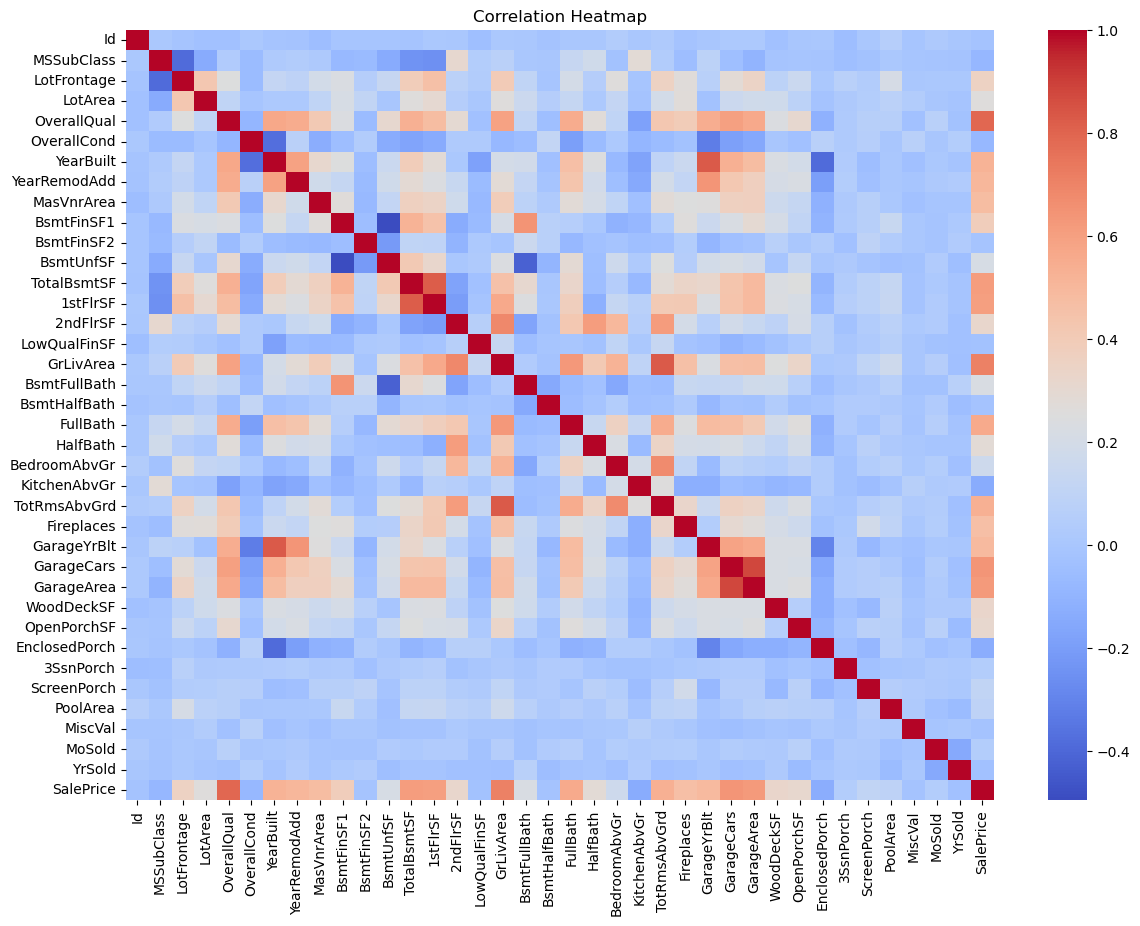

In [13]:
plt.figure(figsize=(14,10))

correlation = df.corr(numeric_only=True)

sns.heatmap(correlation, cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

In [14]:
correlation = df.corr(numeric_only=True)

saleprice_corr = correlation["SalePrice"].sort_values(ascending=False)

saleprice_corr

SalePrice        1.000000
OverallQual      0.790982
GrLivArea        0.708624
GarageCars       0.640409
GarageArea       0.623431
TotalBsmtSF      0.613581
1stFlrSF         0.605852
FullBath         0.560664
TotRmsAbvGrd     0.533723
YearBuilt        0.522897
YearRemodAdd     0.507101
GarageYrBlt      0.486362
MasVnrArea       0.477493
Fireplaces       0.466929
BsmtFinSF1       0.386420
LotFrontage      0.351799
WoodDeckSF       0.324413
2ndFlrSF         0.319334
OpenPorchSF      0.315856
HalfBath         0.284108
LotArea          0.263843
BsmtFullBath     0.227122
BsmtUnfSF        0.214479
BedroomAbvGr     0.168213
ScreenPorch      0.111447
PoolArea         0.092404
MoSold           0.046432
3SsnPorch        0.044584
BsmtFinSF2      -0.011378
BsmtHalfBath    -0.016844
MiscVal         -0.021190
Id              -0.021917
LowQualFinSF    -0.025606
YrSold          -0.028923
OverallCond     -0.077856
MSSubClass      -0.084284
EnclosedPorch   -0.128578
KitchenAbvGr    -0.135907
Name: SalePr

In [15]:
saleprice_corr.head(15)

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
GarageYrBlt     0.486362
MasVnrArea      0.477493
Fireplaces      0.466929
BsmtFinSF1      0.386420
Name: SalePrice, dtype: float64

## Relationship Between Overall Quality and Sale Price

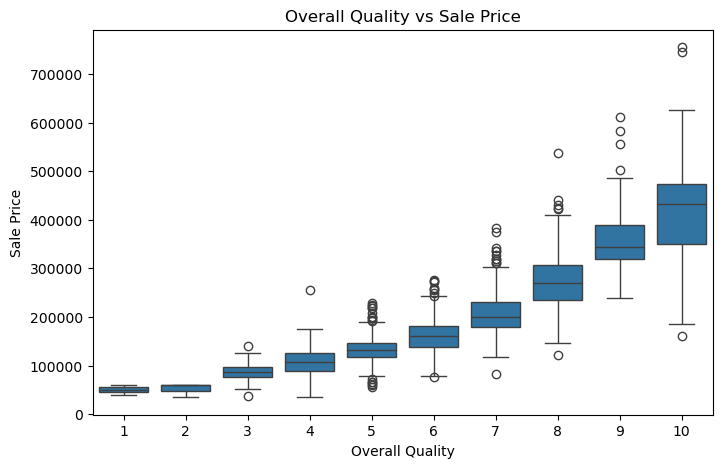

In [16]:
plt.figure(figsize=(8,5))

sns.boxplot(x="OverallQual", y="SalePrice", data=df)

plt.title("Overall Quality vs Sale Price")
plt.xlabel("Overall Quality")
plt.ylabel("Sale Price")

plt.show()

## Observation

The box plot shows a strong positive relationship between **Overall Quality** and **Sale Price**. Houses with higher overall quality ratings generally have higher selling prices. Although there are a few outliers in different quality categories, the overall trend clearly indicates that better construction quality and finishing significantly increase the market value of a house.

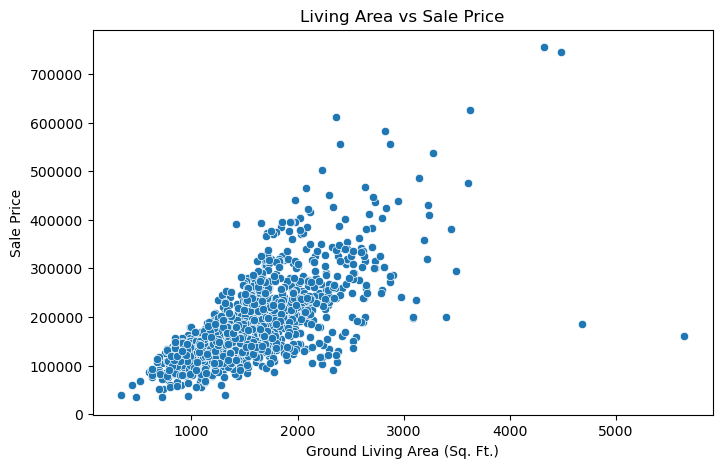

In [17]:
plt.figure(figsize=(8,5))

sns.scatterplot(x="GrLivArea", y="SalePrice", data=df)

plt.title("Living Area vs Sale Price")
plt.xlabel("Ground Living Area (Sq. Ft.)")
plt.ylabel("Sale Price")

plt.show()

## Observation

The scatter plot indicates a strong positive relationship between **Ground Living Area (GrLivArea)** and **Sale Price**. As the living area increases, the selling price of the house generally increases. A few outliers are present, but the overall trend confirms that larger houses tend to have higher market values.

## Relationship Between Neighborhood and Sale Price

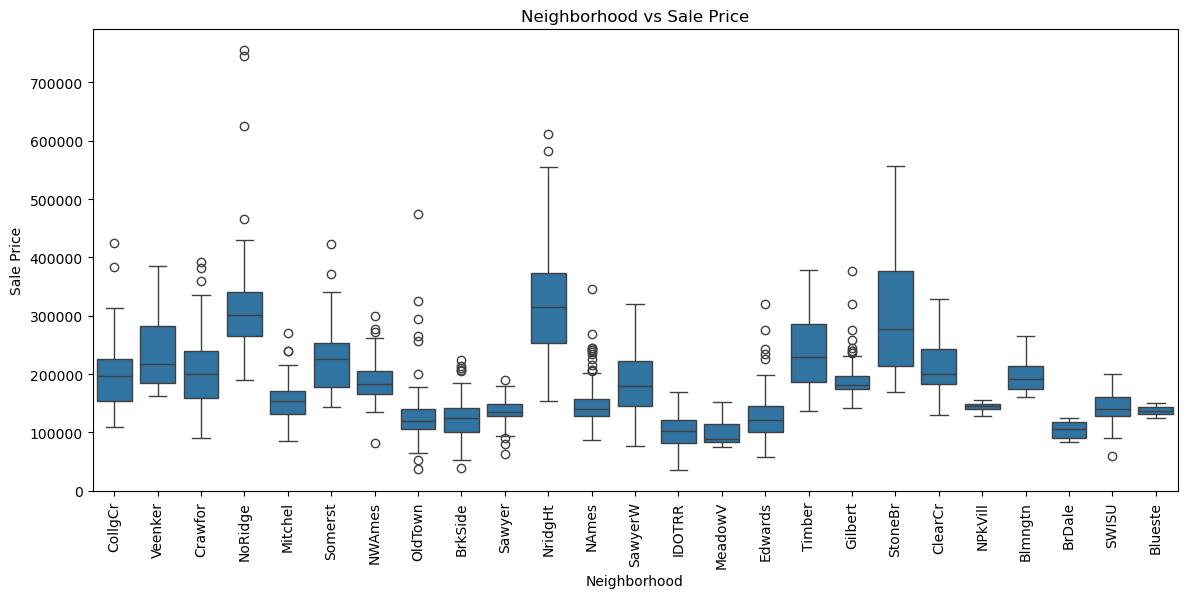

In [18]:
plt.figure(figsize=(14,6))

sns.boxplot(x="Neighborhood", y="SalePrice", data=df)

plt.xticks(rotation=90)

plt.title("Neighborhood vs Sale Price")
plt.xlabel("Neighborhood")
plt.ylabel("Sale Price")

plt.show()

## Observation

The box plot shows that house prices vary significantly across different neighborhoods. Some neighborhoods consistently have higher median sale prices, indicating premium residential areas, while others have lower median prices, making them more affordable. This suggests that the location of a property is an important factor influencing its market value.

## Relationship Between Year Built and Sale Price

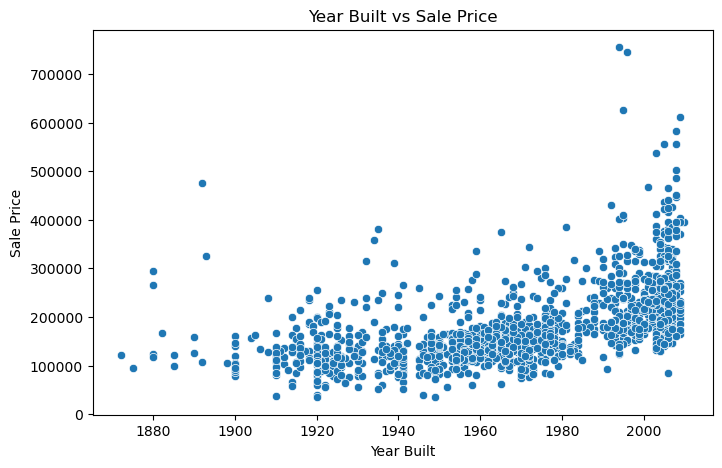

In [19]:
plt.figure(figsize=(8,5))

sns.scatterplot(x="YearBuilt", y="SalePrice", data=df)

plt.title("Year Built vs Sale Price")
plt.xlabel("Year Built")
plt.ylabel("Sale Price")

plt.show()

## Key Insights from Exploratory Data Analysis

## Observation

The scatter plot shows a positive relationship between **Year Built** and **Sale Price**. In general, newer houses tend to have higher selling prices than older houses. Although some older properties also have high prices, the overall trend indicates that recently constructed homes usually have greater market value.

## Relationship Between Garage Capacity and Sale Price

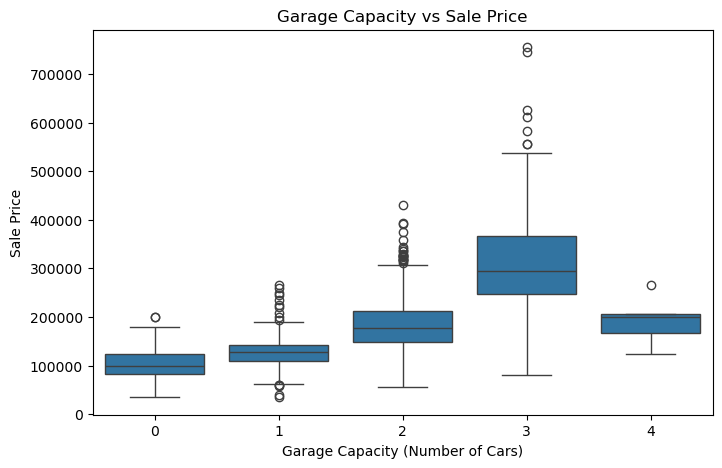

In [20]:
plt.figure(figsize=(8,5))

sns.boxplot(x="GarageCars", y="SalePrice", data=df)

plt.title("Garage Capacity vs Sale Price")
plt.xlabel("Garage Capacity (Number of Cars)")
plt.ylabel("Sale Price")

plt.show()

## Observation

The box plot indicates a positive relationship between **Garage Capacity** and **Sale Price**. Houses with larger garages generally have higher selling prices. This suggests that garage capacity is an important feature that contributes to the overall value of a property.

## Missing Values Analysis

In [22]:
missing_values = df.isnull().sum().sort_values(ascending=False)

missing_values = missing_values[missing_values > 0]

missing_values

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageYrBlt       81
GarageCond        81
GarageType        81
GarageFinish      81
GarageQual        81
BsmtFinType2      38
BsmtExposure      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64

## Key Insights from Exploratory Data Analysis

## Observation

The dataset contains missing values in several features. Some columns, such as **PoolQC**, **MiscFeature**, **Alley**, and **Fence**, have a very high percentage of missing values, while other features like **LotFrontage**, **GarageType**, **GarageFinish**, **GarageQual**, **GarageCond**, **MasVnrArea**, and **Electrical** contain relatively fewer missing values. Appropriate preprocessing techniques will be applied to handle these missing values before model development.

# Data Preprocessing

In [23]:
df = df.drop(
    columns=[
        "PoolQC",
        "MiscFeature",
        "Alley",
        "Fence",
        "MasVnrType",
        "FireplaceQu"
    ]
)

df.shape

(1460, 75)

In [24]:
# Fill numerical missing values with median
df["LotFrontage"].fillna(df["LotFrontage"].median(), inplace=True)
df["GarageYrBlt"].fillna(df["GarageYrBlt"].median(), inplace=True)
df["MasVnrArea"].fillna(df["MasVnrArea"].median(), inplace=True)

# Fill categorical missing values with mode
categorical_columns = [
    "GarageType",
    "GarageFinish",
    "GarageQual",
    "GarageCond",
    "BsmtQual",
    "BsmtCond",
    "BsmtExposure",
    "BsmtFinType1",
    "BsmtFinType2",
    "Electrical"
]

for col in categorical_columns:
    df[col].fillna(df[col].mode()[0], inplace=True)

In [25]:
df.isnull().sum().sort_values(ascending=False)

Id              0
GarageYrBlt     0
Fireplaces      0
Functional      0
TotRmsAbvGrd    0
               ..
MasVnrArea      0
Exterior2nd     0
Exterior1st     0
RoofMatl        0
SalePrice       0
Length: 75, dtype: int64

## Observation

Data preprocessing was successfully completed by removing features with excessive missing values and imputing the remaining missing values using appropriate techniques. Numerical features were filled using the median, while categorical features were filled using the mode. The dataset is now complete and ready for feature encoding and machine learning model development.

# Feature Engineering

In [26]:
df = pd.get_dummies(df, drop_first=True)

df.shape

(1460, 231)

## Observation

Feature engineering was successfully performed by converting all categorical variables into numerical format using one-hot encoding. This increased the total number of features from **75** to **231**, making the dataset suitable for machine learning regression models.

# Train-Test Split

In [27]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (1460, 230)
Target Shape   : (1460,)


## Observation

The dataset was successfully divided into independent features (`X`) and the target variable (`y`). After feature engineering, the dataset contains **230 input features** that will be used to train the regression models, while **SalePrice** is retained as the target variable for prediction.

In [28]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training Features :", X_train.shape)
print("Testing Features  :", X_test.shape)
print("Training Target   :", y_train.shape)
print("Testing Target    :", y_test.shape)

Training Features : (1168, 230)
Testing Features  : (292, 230)
Training Target   : (1168,)
Testing Target    : (292,)


## Observation

The dataset was successfully divided into training and testing sets using an 80:20 ratio. The training dataset will be used to train the regression models, while the testing dataset will be used to evaluate their performance on unseen data.

# Linear Regression

In [29]:
lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [30]:
y_pred_lr = lr_model.predict(X_test)

In [31]:
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Mean Absolute Error (MAE) :", mae_lr)
print("Root Mean Squared Error (RMSE) :", rmse_lr)
print("R² Score :", r2_lr)

Mean Absolute Error (MAE) : 20384.191689711413
Root Mean Squared Error (RMSE) : 51992.046446799555
R² Score : 0.6475804521594819


Mean Absolute Error (MAE) : 20384.191689711413
Root Mean Squared Error (RMSE) : 51992.046446799555
R² Score : 0.6475804521594819

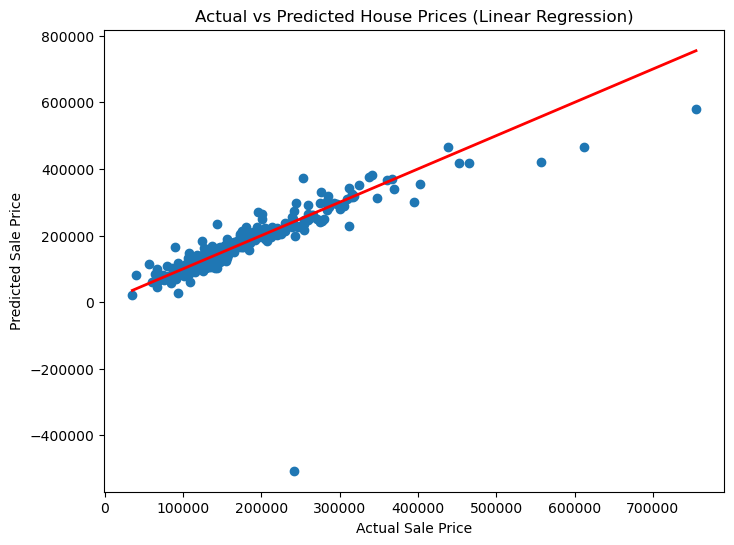

In [32]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_lr)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.title("Actual vs Predicted House Prices (Linear Regression)")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")

plt.show()

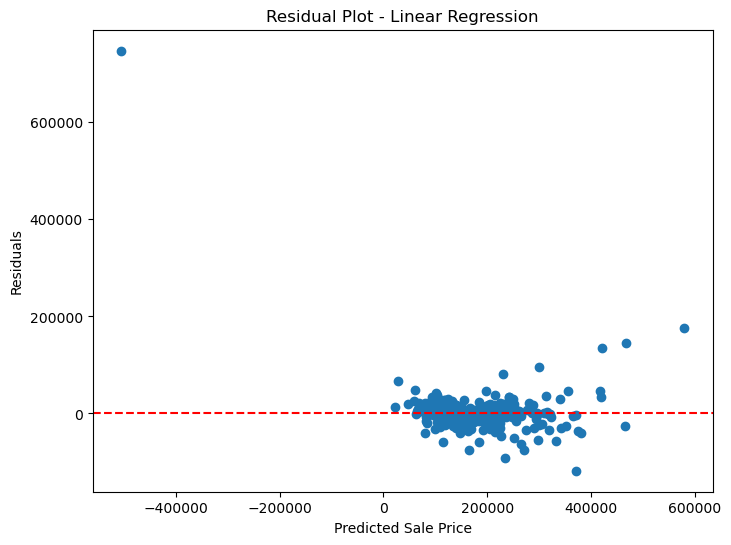

In [33]:
residuals = y_test - y_pred_lr

plt.figure(figsize=(8,6))

plt.scatter(y_pred_lr, residuals)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residual Plot - Linear Regression")
plt.xlabel("Predicted Sale Price")
plt.ylabel("Residuals")

plt.show()

# Decision Tree Regressor

In [34]:
dt_model = DecisionTreeRegressor(random_state=42)

dt_model.fit(X_train, y_train)

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [35]:
y_pred_dt = dt_model.predict(X_test)

In [36]:
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Mean Absolute Error (MAE) :", mae_dt)
print("Root Mean Squared Error (RMSE) :", rmse_dt)
print("R² Score :", r2_dt)

Mean Absolute Error (MAE) : 27553.852739726026
Root Mean Squared Error (RMSE) : 42232.68346677481
R² Score : 0.7674675750904107


## Observation

The Decision Tree Regressor achieved a **Mean Absolute Error (MAE) of 27,553.85**, a **Root Mean Squared Error (RMSE) of 42,232.68**, and an **R² Score of 0.767**. Compared to the Linear Regression model, the Decision Tree explained a larger proportion of the variance in house prices and achieved a lower RMSE, indicating better overall predictive performance.

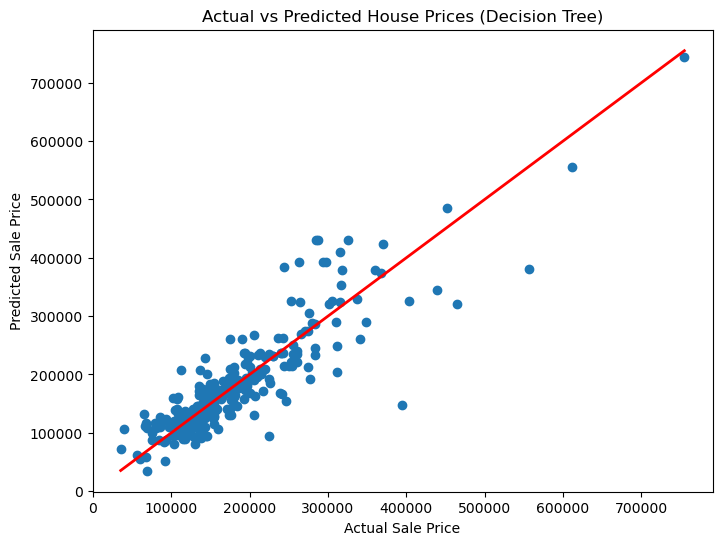

In [37]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_dt)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.title("Actual vs Predicted House Prices (Decision Tree)")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")

plt.show()

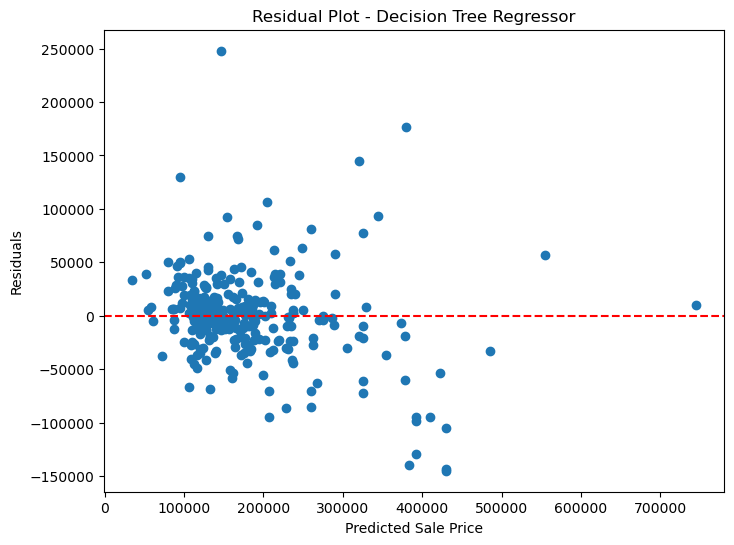

In [38]:
residuals_dt = y_test - y_pred_dt

plt.figure(figsize=(8,6))

plt.scatter(y_pred_dt, residuals_dt)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residual Plot - Decision Tree Regressor")
plt.xlabel("Predicted Sale Price")
plt.ylabel("Residuals")

plt.show()

# Random Forest Regressor

In [41]:
rf_model = RandomForestRegressor(random_state=42)

rf_model.fit(X_train, y_train)

,n_estimators,100
,criterion,'squared_error'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [42]:
y_pred_rf = rf_model.predict(X_test)

In [43]:
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Mean Absolute Error (MAE) :", mae_rf)
print("Root Mean Squared Error (RMSE) :", rmse_rf)
print("R² Score :", r2_rf)

Mean Absolute Error (MAE) : 17658.598219178082
Root Mean Squared Error (RMSE) : 29061.615221754313
R² Score : 0.8898902789159175


## Observation

The Random Forest Regressor achieved the best performance among the models evaluated so far. It recorded a **Mean Absolute Error (MAE) of 17,658.60**, a **Root Mean Squared Error (RMSE) of 29,061.62**, and an **R² Score of 0.890**. These results indicate that the model predicts house prices with high accuracy and explains nearly 89% of the variation in the target variable, making it the strongest model evaluated so far.

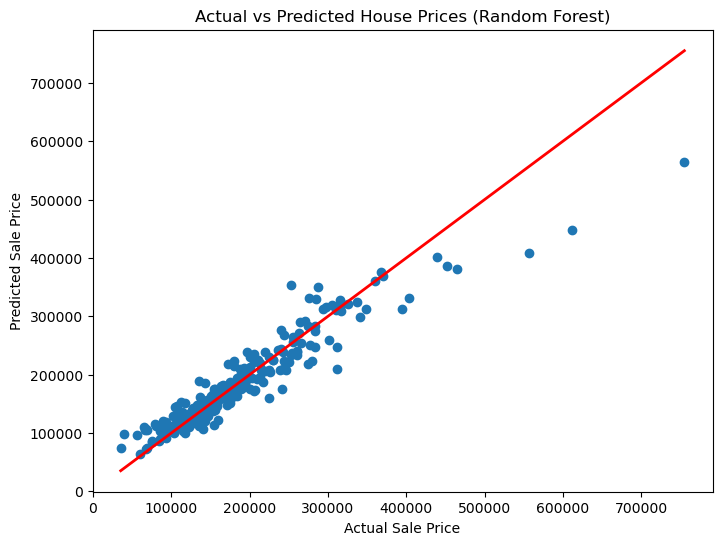

In [44]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_rf)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.title("Actual vs Predicted House Prices (Random Forest)")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")

plt.show()

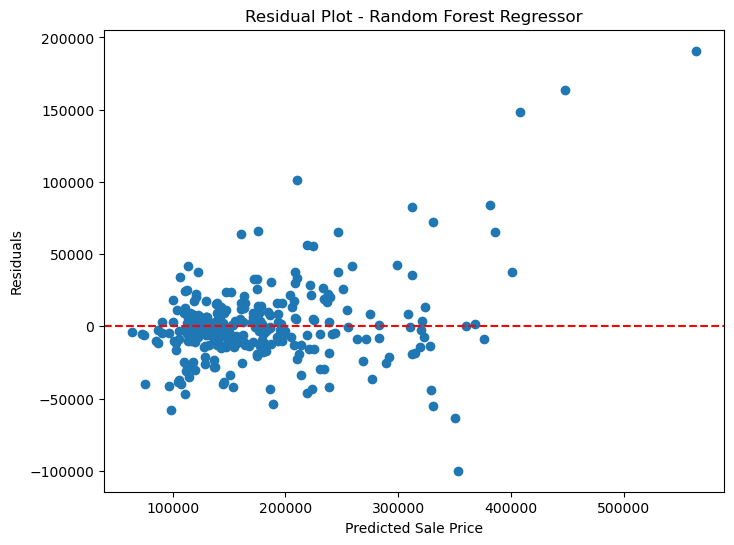

In [45]:
residuals_rf = y_test - y_pred_rf

plt.figure(figsize=(8,6))

plt.scatter(y_pred_rf, residuals_rf)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residual Plot - Random Forest Regressor")
plt.xlabel("Predicted Sale Price")
plt.ylabel("Residuals")

plt.show()

In [46]:
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
4,OverallQual,0.557312
16,GrLivArea,0.120895
14,2ndFlrSF,0.034139
12,TotalBsmtSF,0.034134
9,BsmtFinSF1,0.029357
13,1stFlrSF,0.025763
3,LotArea,0.017886
27,GarageArea,0.016116
26,GarageCars,0.012533
6,YearBuilt,0.011213


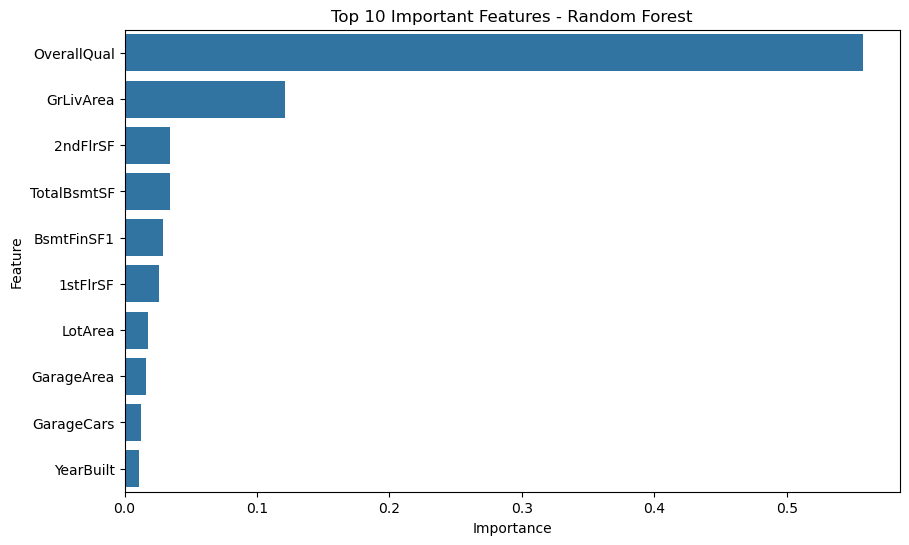

In [47]:
plt.figure(figsize=(10,6))

sns.barplot(
    x="Importance",
    y="Feature",
    data=feature_importance.head(10)
)

plt.title("Top 10 Important Features - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Feature")

plt.show()

## Observation

The Random Forest feature importance analysis shows that **OverallQual** is the most influential feature in predicting house prices, followed by **GrLivArea**, **2ndFlrSF**, **TotalBsmtSF**, and **BsmtFinSF1**. This indicates that the overall quality of a house, its living area, basement size, and construction-related features play a significant role in determining its market value.

# Gradient Boosting Regressor

In [48]:
gb_model = GradientBoostingRegressor(random_state=42)

gb_model.fit(X_train, y_train)

,loss,'squared_error'
,learning_rate,0.1
,n_estimators,100
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [49]:
y_pred_gb = gb_model.predict(X_test)

In [50]:
mae_gb = mean_absolute_error(y_test, y_pred_gb)
rmse_gb = np.sqrt(mean_squared_error(y_test, y_pred_gb))
r2_gb = r2_score(y_test, y_pred_gb)

print("Mean Absolute Error (MAE) :", mae_gb)
print("Root Mean Squared Error (RMSE) :", rmse_gb)
print("R² Score :", r2_gb)

Mean Absolute Error (MAE) : 17468.114195834944
Root Mean Squared Error (RMSE) : 27950.316590028757
R² Score : 0.8981503294148259


## Observation

The Gradient Boosting Regressor achieved the best performance among all the models evaluated. It recorded a **Mean Absolute Error (MAE) of 17,468.11**, a **Root Mean Squared Error (RMSE) of 27,950.32**, and an **R² Score of 0.898**. These results indicate that the model predicts house prices with high accuracy and explains approximately 89.8% of the variation in house prices, making it the most effective model for this dataset.

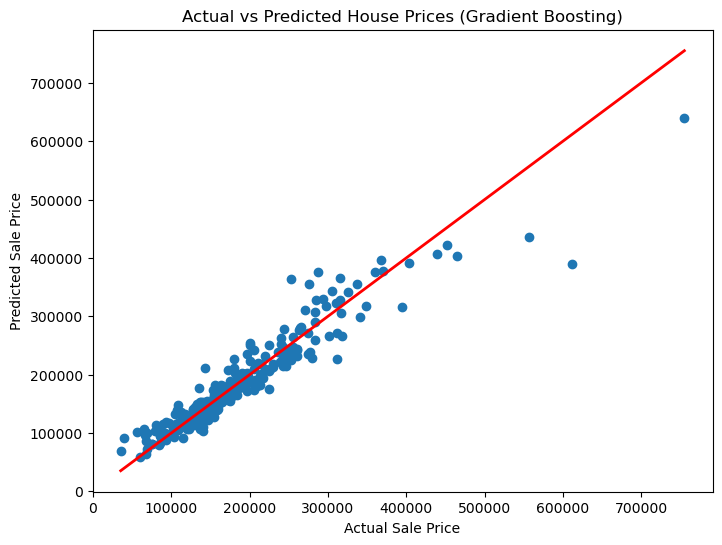

In [51]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred_gb)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.title("Actual vs Predicted House Prices (Gradient Boosting)")
plt.xlabel("Actual Sale Price")
plt.ylabel("Predicted Sale Price")

plt.show()

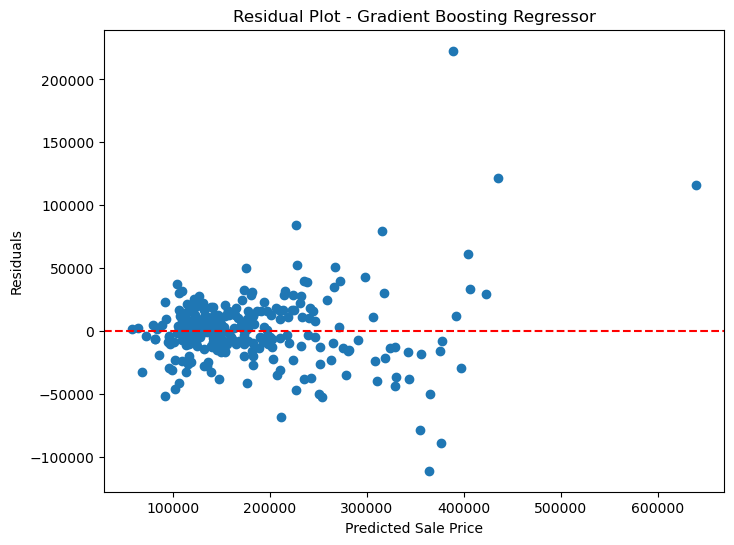

In [52]:
residuals_gb = y_test - y_pred_gb

plt.figure(figsize=(8,6))

plt.scatter(y_pred_gb, residuals_gb)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residual Plot - Gradient Boosting Regressor")
plt.xlabel("Predicted Sale Price")
plt.ylabel("Residuals")

plt.show()

In [53]:
comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        mae_lr,
        mae_dt,
        mae_rf,
        mae_gb
    ],
    "RMSE": [
        rmse_lr,
        rmse_dt,
        rmse_rf,
        rmse_gb
    ],
    "R2 Score": [
        r2_lr,
        r2_dt,
        r2_rf,
        r2_gb
    ]
})

comparison

,Model,MAE,RMSE,R2 Score
0,Linear Regression,20384.191690,51992.046447,0.647580
1,Decision Tree,27553.852740,42232.683467,0.767468
2,Random Forest,17658.598219,29061.615222,0.889890
3,Gradient Boosting,17468.114196,27950.316590,0.898150


## Model Comparison

Among all the regression models evaluated, the **Gradient Boosting Regressor** achieved the best performance with the **lowest MAE (17,468.11)**, the **lowest RMSE (27,950.32)**, and the **highest R² Score (0.898)**. This indicates that Gradient Boosting provides the most accurate predictions for house prices in this dataset. Therefore, it is selected as the final model for house price prediction.

# Customer Recommendations

- Focus on improving the **overall quality** of the property, as it has the greatest influence on house prices.
- Increasing the **living area** through renovations or extensions can significantly improve the property's market value.
- Maintaining or upgrading the **basement and garage** can positively impact the selling price.
- Regular renovation and modernization of older houses can increase their market competitiveness.
- Home buyers should consider features such as **overall quality, living area, garage capacity, and construction year** when evaluating a property's value.
- Based on the model comparison, the **Gradient Boosting Regressor** is recommended for predicting house prices because it achieved the highest prediction accuracy.

# Challenges Faced

- The dataset contained several missing values, which required careful preprocessing before model development.
- A large number of categorical variables had to be converted into numerical format using one-hot encoding.
- Selecting the most suitable regression model required comparing multiple algorithms using different evaluation metrics.
- Some models performed better on certain metrics than others, making model comparison an important step in selecting the final model.
- Understanding the relationship between different house features and sale price required detailed exploratory data analysis and visualization.

# Conclusion

This project successfully developed and evaluated multiple machine learning regression models for predicting house prices. Exploratory Data Analysis (EDA) identified important factors influencing house prices, including overall quality, living area, neighborhood, garage capacity, and year built. After preprocessing the data and applying feature engineering, four regression models were trained and evaluated.

Among all the models, the **Gradient Boosting Regressor** achieved the best performance with an **R² Score of 0.898**, the **lowest Mean Absolute Error (MAE)**, and the **lowest Root Mean Squared Error (RMSE)**. These results indicate that the model can accurately predict house prices and can be effectively used for real estate price estimation and decision-making.